In [298]:
%matplotlib inline

from pathlib import Path 

import numpy as np
import pandas as pd

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
import matplotlib.colorizer as mcolorizer
import matplotlib.lines as mlines
import matplotlib.collections as mcolls

from mpl_toolkits.mplot3d import Axes3D, art3d
from matplotlib.offsetbox import AnnotationBbox, DrawingArea, OffsetImage, TextArea

import cmocean

import papercolors as pc
from papercolors import colordict as pcd

import homeomorphism_helpers as hh
from homeomorphism_helpers import fs

paper_path = Path('../figures/slide_intro/')

fs={'normal': 10, 'small':9, 'footnote':8, 'script':7, 'tiny':5, 'heading':12}
fs = {k:v+2 for (k,v) in fs.items()}

In [299]:
px_width, px_height = 2130, 1200
dpi_value = 500

# 2. Convert pixels to inches inline
px = 1 / dpi_value
figsize=(px_width * px, px_height * px)

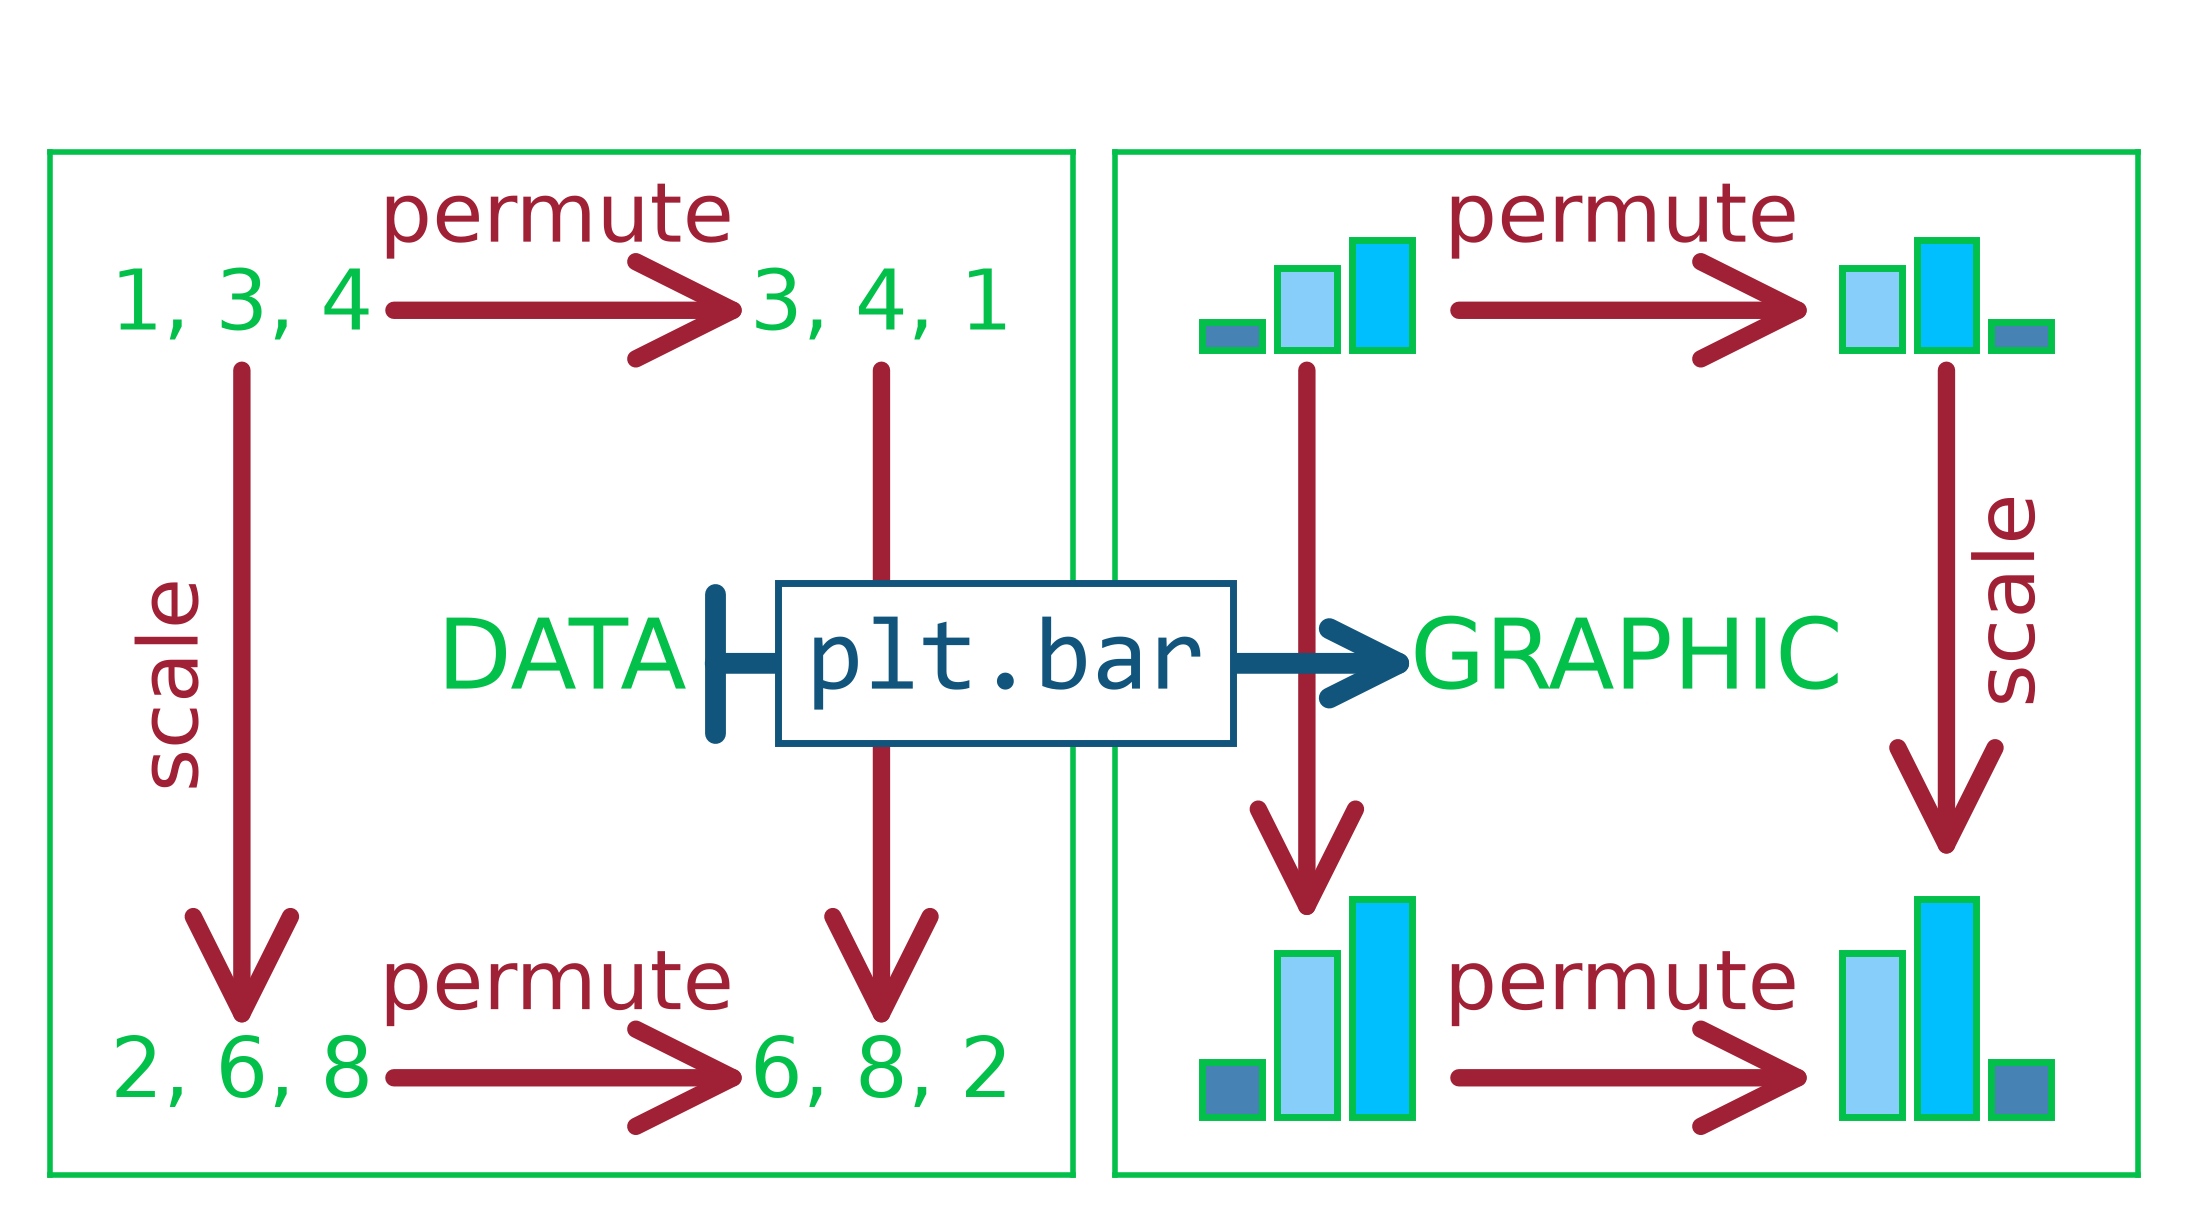

In [300]:
fig = plt.figure(figsize=figsize, dpi=dpi_value, layout="compressed")

axd = fig.subplot_mosaic([['num_shuffle', 'scale_shuffle']])
scale = lambda v : [vi * 2 for vi in v]
shuffle = lambda v : [v[i] for i in [1,2,0]]

clist = [hh.airports['jfk_color'], hh.airports['lga_color'], hh.airports['time_color']]

arrowprops=dict(arrowstyle="->,widthA=.15,lengthA=0", lw=2.5, mutation_scale=35, color=pcd['action'])
x1 = np.linspace(.075,.3, 3)
x2 = np.linspace(.7, 1-.075, 3)
vals, order = hh._get_bar_data(df)
vals = 1,3,4
axins = {'scale_shuffle':{}, 'num_shuffle':{}}

for axn in axins:
    axd[axn].set(xlim=(0,1), ylim=(0,1), xticks=[], yticks=[], aspect='equal')
    axd[axn].spines[:].set_color(pcd['section'])
    axins[axn]['as00'] = axd[axn].inset_axes([x1[0], .8, x1[-1]-x1[0], .3])
    axins[axn]['as01'] = axd[axn].inset_axes([x2[0], .8, x2[-1]-x2[0], .3])
    axins[axn]['as10'] = axd[axn].inset_axes([x1[0], .05, x1[-1]-x1[0], .3])
    axins[axn]['as11'] = axd[axn].inset_axes([x2[0], .05, x2[-1]-x2[0], .3])

    for axs in axins[axn].values():
        axs.set(ylim=(-.25, 11))
        axs.axis('off')

fvals = lambda vals: f"{vals[0]:d}, {vals[1]:d}, {vals[2]:d}"
axins['scale_shuffle']['b00'] = axins['scale_shuffle']['as00'].bar([0,1,2], vals, color=clist, edgecolor=pcd['section'])
axins['num_shuffle']['b00'] = axins['num_shuffle']['as00'].text(.5, 0, fvals(vals), 
                                                                ha='center', va='bottom', fontsize=fs['normal'], color=pcd['section'])

assert shuffle(scale(vals)) == scale(shuffle(vals))
vals1 = shuffle(scale(vals))
axins['scale_shuffle']['b11'] = axins['scale_shuffle']['as11'].bar([0,1,2], vals1, color=shuffle(clist), edgecolor=pcd['section'])
axins['num_shuffle']['b11'] = axins['num_shuffle']['as11'].text(.5, 0, fvals(vals1), 
                                                                ha='center', va='bottom', fontsize=fs['normal'], color=pcd['section'])

vals3 = scale(vals)

axins['scale_shuffle']['b10'] = axins['scale_shuffle']['as10'].bar([0, 1, 2], vals3 , color=clist, edgecolor=pcd['section'])
axins['num_shuffle']['b10'] = axins['num_shuffle']['as10'].text(.5,  0, fvals(vals3), 
                                                                ha='center', va='bottom', fontsize=fs['normal'], color=pcd['section'])

vals4 = shuffle(vals)
axins['scale_shuffle']['b01'] = axins['scale_shuffle']['as01'].bar([0, 1, 2], vals4, color=shuffle(clist), edgecolor=pcd['section'])
axins['num_shuffle']['b01'] = axins['num_shuffle']['as01'].text(.5, 0, fvals(vals4), 
                                                                ha='center', va='bottom', fontsize=fs['normal'], color=pcd['section'])


for axn in axins:
    for (head, tail) in [('as01', 'as00'), ('as11', 'as10')]:
        c = axd[axn].annotate(f"",xy=(0,.15), xytext=(1 if axn.startswith('shuffle') else 1.1, .15), 
                                          xycoords=axins[axn][head], textcoords=axins[axn][tail],
                                          arrowprops=arrowprops)
        ca = axd[axn].annotate(r"permute", (.5, 1), xycoords=c, 
                                           va="bottom", ha="center", color=pcd['action'], fontsize=fs['normal'])

    # scale:  annotate: head, tail, tail=text, xy=head
    for (head, tail) in [('as10', 'as00'), ('as11', 'as01')]:
        
        yb = axins['scale_shuffle'][f'b{head[2:]}'][1].get_height()
        c = axd[axn].annotate(f"",xy=(.5, yb/10 if axn.startswith('scale') else .25), xytext=(.5, 0), 
                                          xycoords=axins[axn][head], textcoords=axins[axn][tail],
                                          arrowprops=arrowprops)
        
        if (axn.startswith("num") and head.endswith("11")) or (axn.startswith('scale') and head.endswith("10")):
            continue
        ca = axd[axn].annotate(r"scale",   (.25 if axn.startswith("num") else .75, .5), xycoords=c,                                        
                                           ha='right' if axn.startswith("num") else "left", va='center', rotation=90, 
                                       color=pcd['action'], fontsize=fs['normal'])


d = axd['num_shuffle'].text(.5, .5, "DATA", color=pcd['section'], fontsize=fs['heading'], transform=axd['num_shuffle'].transAxes, 
                        va='center', ha='center')

g = axd['scale_shuffle'].text(.5, .5, "GRAPHIC", color=pcd['section'], fontsize=fs['heading'], transform=axd['scale_shuffle'].transAxes, 
                        va='center', ha='center')

f = mpatches.ConnectionPatch(xyA=(.65,.5), xyB=(.3,.5),
                    coordsA=axd['num_shuffle'].transAxes, coordsB=axd['scale_shuffle'].transAxes,
                    arrowstyle=']->,lengthA=0, widthA=.4', color=pcd['artist'], lw=3, mutation_scale=25)
fig.add_artist(f)

# Annotate the ConnectionPatch position ('Test 1')
offsetbox = TextArea("plt.bar", textprops={'color':pcd['artist'], 'fontsize':fs['heading']+1, 'font':'consolas'})

# place the annotation above the midpoint of c
ab1 = AnnotationBbox(offsetbox,
                     xy=(.425, .5),
                     xybox=(0, 0),
                     xycoords=f,
                     boxcoords="offset points",
                     bboxprops=dict(facecolor='white', edgecolor=pcd['artist']),
                     )
fig.add_artist(ab1)
fig.savefig("aizenman_2130X1200.png", dpi=dpi_value, bbox_inches='tight')

In [414]:
def slide_intro(slide):
    fig = plt.figure(figsize=(10, 5), dpi=500, layout="compressed")
    
    axd = fig.subplot_mosaic([['num_shuffle', '.', 'scale_shuffle']])
    scale = lambda v : [vi * 2 for vi in v]
    shuffle = lambda v : [v[i] for i in [1,2,0]]
    
    clist = [hh.airports['jfk_color'], hh.airports['lga_color'], hh.airports['time_color']]
    
    arrowprops=dict(arrowstyle="->,widthA=.15,lengthA=0", lw=2.5, mutation_scale=35, color=pcd['action'])
    x1 = np.linspace(.075,.3, 3)
    x2 = np.linspace(.7, 1-.075, 3)
    vals, order = hh._get_bar_data(df)
    vals = 1,3,4
    
    fvals = lambda vals: f"{vals[0]:d}, {vals[1]:d}, {vals[2]:d}"

    axins = {'scale_shuffle':{}, 'num_shuffle':{}}
    
    for axn in axins:
        axd[axn].set(xlim=(0,1), ylim=(0,1), xticks=[], yticks=[], aspect='equal')
        axd[axn].spines[:].set_color(pcd['section'])
    
    if slide > 1:
        for axn in axins:
            axins[axn]['as00'] = axd[axn].inset_axes([x1[0], .8, x1[-1]-x1[0], .3])
            axins[axn]['as01'] = axd[axn].inset_axes([x2[0], .8, x2[-1]-x2[0], .3])
            axins[axn]['as10'] = axd[axn].inset_axes([x1[0], .05, x1[-1]-x1[0], .3])
            axins[axn]['as11'] = axd[axn].inset_axes([x2[0], .05, x2[-1]-x2[0], .3])
        
            for axs in axins[axn].values():
                axs.set(ylim=(-.25, 11))
                axs.axis('off')
        
        if slide>2:        
            axins['scale_shuffle']['b00'] = axins['scale_shuffle']['as00'].bar([0,1,2], vals, color=clist, edgecolor=pcd['section'])

   
        axins['num_shuffle']['b00'] = axins['num_shuffle']['as00'].text(.5, 0, fvals(vals), 
                                                                        ha='center', va='bottom', fontsize=fs['normal'], color=pcd['section'])
        
        assert shuffle(scale(vals)) == scale(shuffle(vals))
        vals1 = shuffle(scale(vals))
        if slide>2:
            axins['scale_shuffle']['b11'] = axins['scale_shuffle']['as11'].bar([0,1,2], vals1, color=shuffle(clist), edgecolor=pcd['section'])
        
        axins['num_shuffle']['b11'] = axins['num_shuffle']['as11'].text(.5, 0, fvals(vals1), 
                                                                        ha='center', va='bottom', fontsize=fs['normal'], color=pcd['section'])
        
        vals3 = scale(vals)

        if slide>2:
            axins['scale_shuffle']['b10'] = axins['scale_shuffle']['as10'].bar([0, 1, 2], vals3 , color=clist, edgecolor=pcd['section'])
        
        axins['num_shuffle']['b10'] = axins['num_shuffle']['as10'].text(.5,  0, fvals(vals3), 
                                                                        ha='center', va='bottom', fontsize=fs['normal'], color=pcd['section'])
        
        vals4 = shuffle(vals)
        if slide>2:
            axins['scale_shuffle']['b01'] = axins['scale_shuffle']['as01'].bar([0, 1, 2], vals4, color=shuffle(clist), edgecolor=pcd['section'])
        axins['num_shuffle']['b01'] = axins['num_shuffle']['as01'].text(.5, 0, fvals(vals4), 
                                                                        ha='center', va='bottom', fontsize=fs['normal'], color=pcd['section'])
        
        
        for axn in axins:
            if slide == 2 and axn == 'scale_shuffle': 
                continue
            
            for (head, tail) in [('as01', 'as00'), ('as11', 'as10')]:
                c = axd[axn].annotate(f"",xy=(0,.15), xytext=(1 if axn.endswith('shuffle') else 1.1, .15), 
                                                  xycoords=axins[axn][head], textcoords=axins[axn][tail],
                                                  arrowprops=arrowprops)
                ca = axd[axn].annotate(r"permute", (.5, 1), xycoords=c, 
                                                   va="bottom", ha="center", color=pcd['action'], fontsize=fs['normal'])
        
            # scale:  annotate: head, tail, tail=text, xy=head
            for (head, tail) in [('as10', 'as00'), ('as11', 'as01')]:
                yb = .25 if not axn.startswith('scale') else axins['scale_shuffle'][f'b{head[2:]}'][1].get_height()/10
               
                
                c = axd[axn].annotate(f"",xy=(.5, yb) , xytext=(.5, 0), 
                                                  xycoords=axins[axn][head], textcoords=axins[axn][tail],
                                                  arrowprops=arrowprops)
                
                if (axn.startswith("num") and head.endswith("11")) or (axn.startswith('scale') and head.endswith("10")):
                    continue
                ca = axd[axn].annotate(r"scale",   (.25 if axn.startswith("num") else .75, .5), xycoords=c,                                        
                                                   ha='right' if axn.startswith("num") else "left", va='center', rotation=90, 
                                               color=pcd['action'], fontsize=fs['normal'])
    if slide in [0,1]:
        d = axd['num_shuffle'].text(.5, .5, fvals(vals), color=pcd['section'], fontsize=fs['heading']+25, transform=axd['num_shuffle'].transAxes, 
                                    va='center', ha='center')
        g = axd['scale_shuffle'].bar([0,1,2], vals, color=clist, edgecolor=pcd['section'])
        axd['scale_shuffle'].set(xlim=(-1.5, 3.5), ylim=(0,5), aspect='equal')
    
    else:
        d = axd['num_shuffle'].text(.5, .5, "DATA", color=pcd['section'], fontsize=fs['heading'], transform=axd['num_shuffle'].transAxes, 
                                    va='center', ha='center')
        if slide >3:
            g = axd['scale_shuffle'].text(.5, .5, "GRAPHIC", color=pcd['section'], fontsize=fs['heading'], 
                                          transform=axd['scale_shuffle'].transAxes, va='center', ha='center')

    if slide == 2:
        axd['scale_shuffle'].axis('off')
        
    arrowstyle = ']->,lengthA=2.5, widthA=.25' if slide > 1 else ']->,lengthA= 0, widthA=.15' 
    f = mpatches.ConnectionPatch(xyA=(1.025,.5), xyB=(0,.5),
                        coordsA=axd['num_shuffle'].transAxes, coordsB=axd['scale_shuffle'].transAxes,
                        arrowstyle=arrowstyle, color=pcd['artist'], lw=5, 
                                 mutation_scale=100, mutation_aspect=5)
    if slide not in [2, 3]:
        fig.add_artist(f) 
    
    if slide not in [0,2,3,4]:
        # Annotate the ConnectionPatch position ('Test 1')
        offsetbox = TextArea("plt.bar", textprops={'color':pcd['artist'], 'fontsize':fs['heading']+30, 'font':'consolas'})
        
        # place the annotation above the midpoint of c
        ab1 = AnnotationBbox(offsetbox,
                             xy=(.75 if slide >1  else .5, .5),
                             xybox=(0, 0),
                             xycoords=f,
                             boxcoords="offset points",
                             bboxprops=dict(facecolor='white', edgecolor=pcd['artist'], lw=5),
                             )
        
        fig.add_artist(ab1)

    fig.savefig(paper_path/f"intro_slide_{slide}.pdf", dpi=dpi_value, bbox_inches='tight')

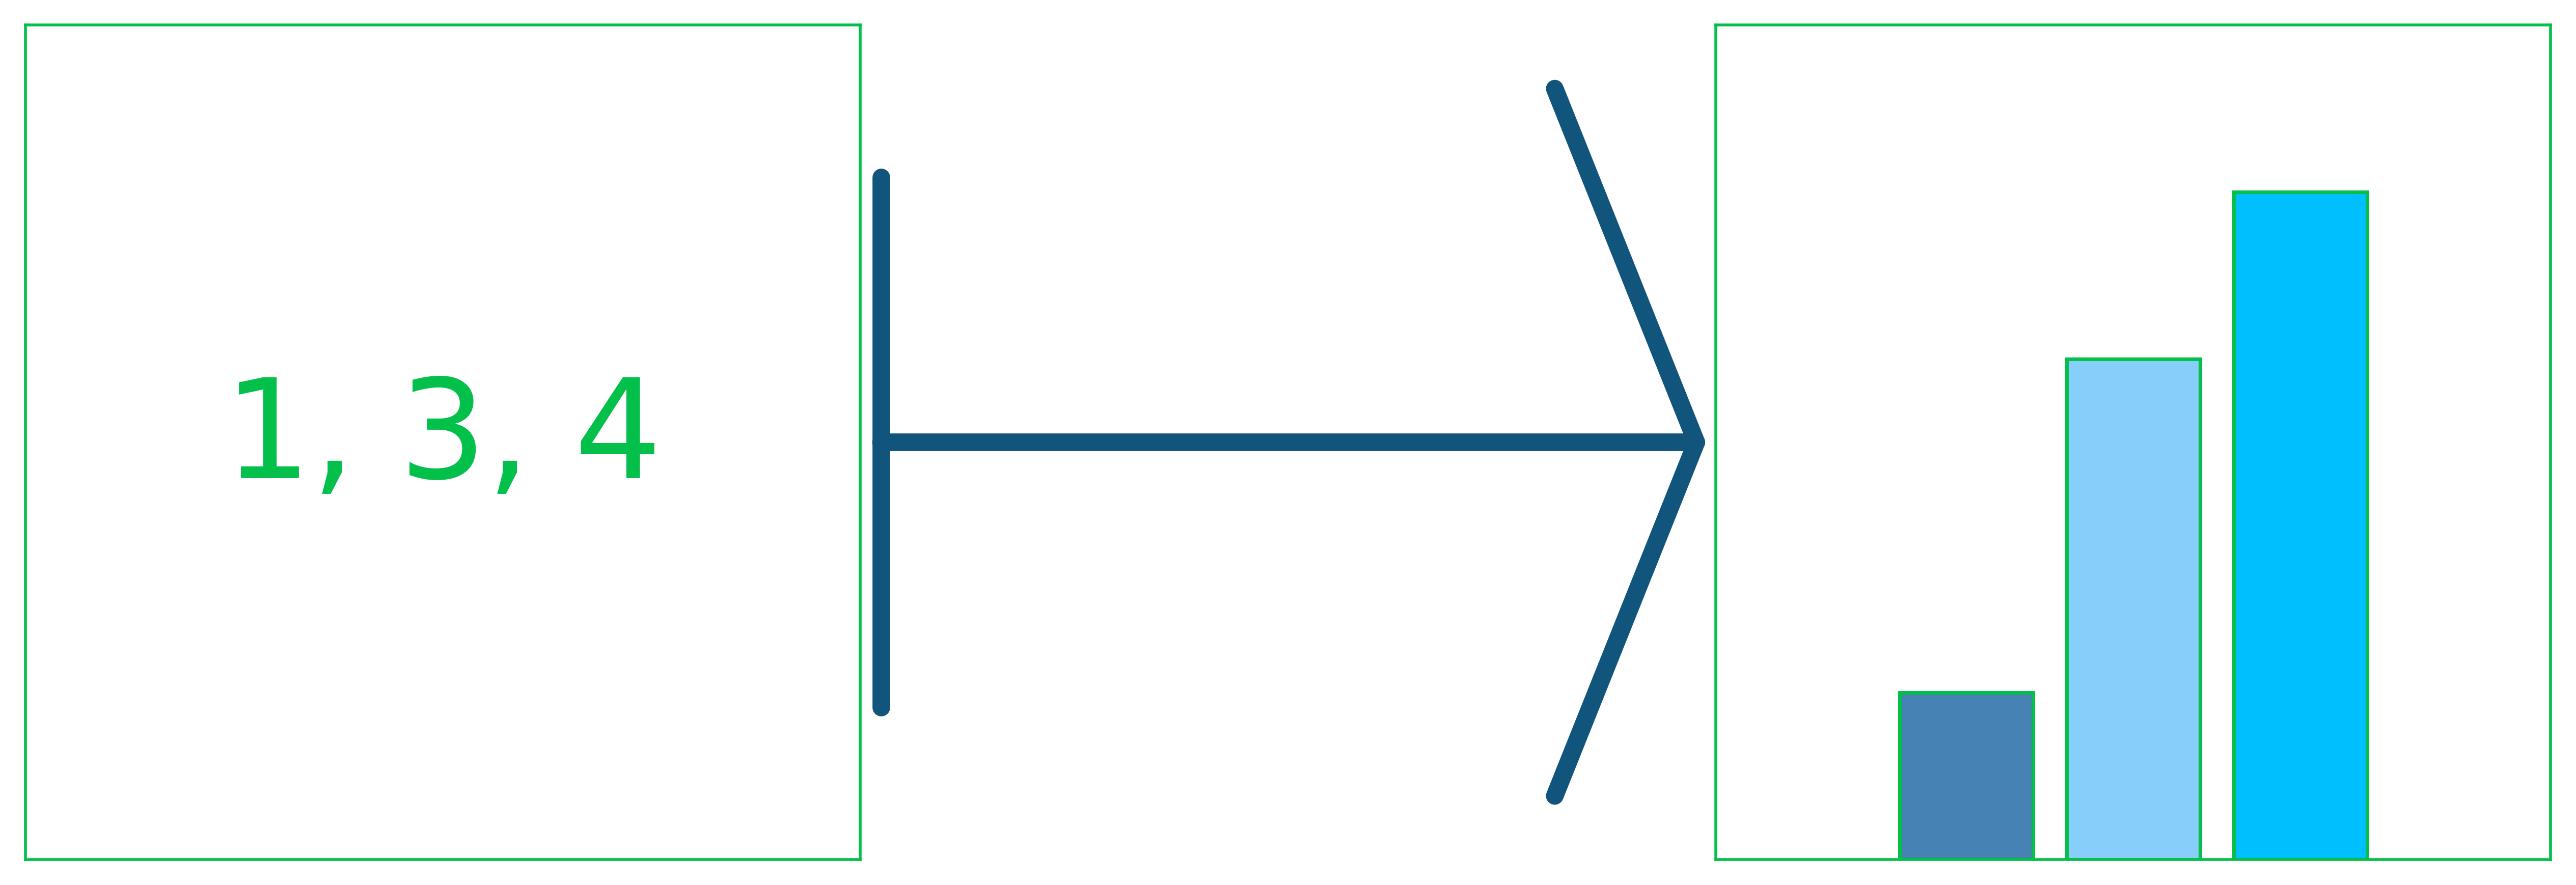

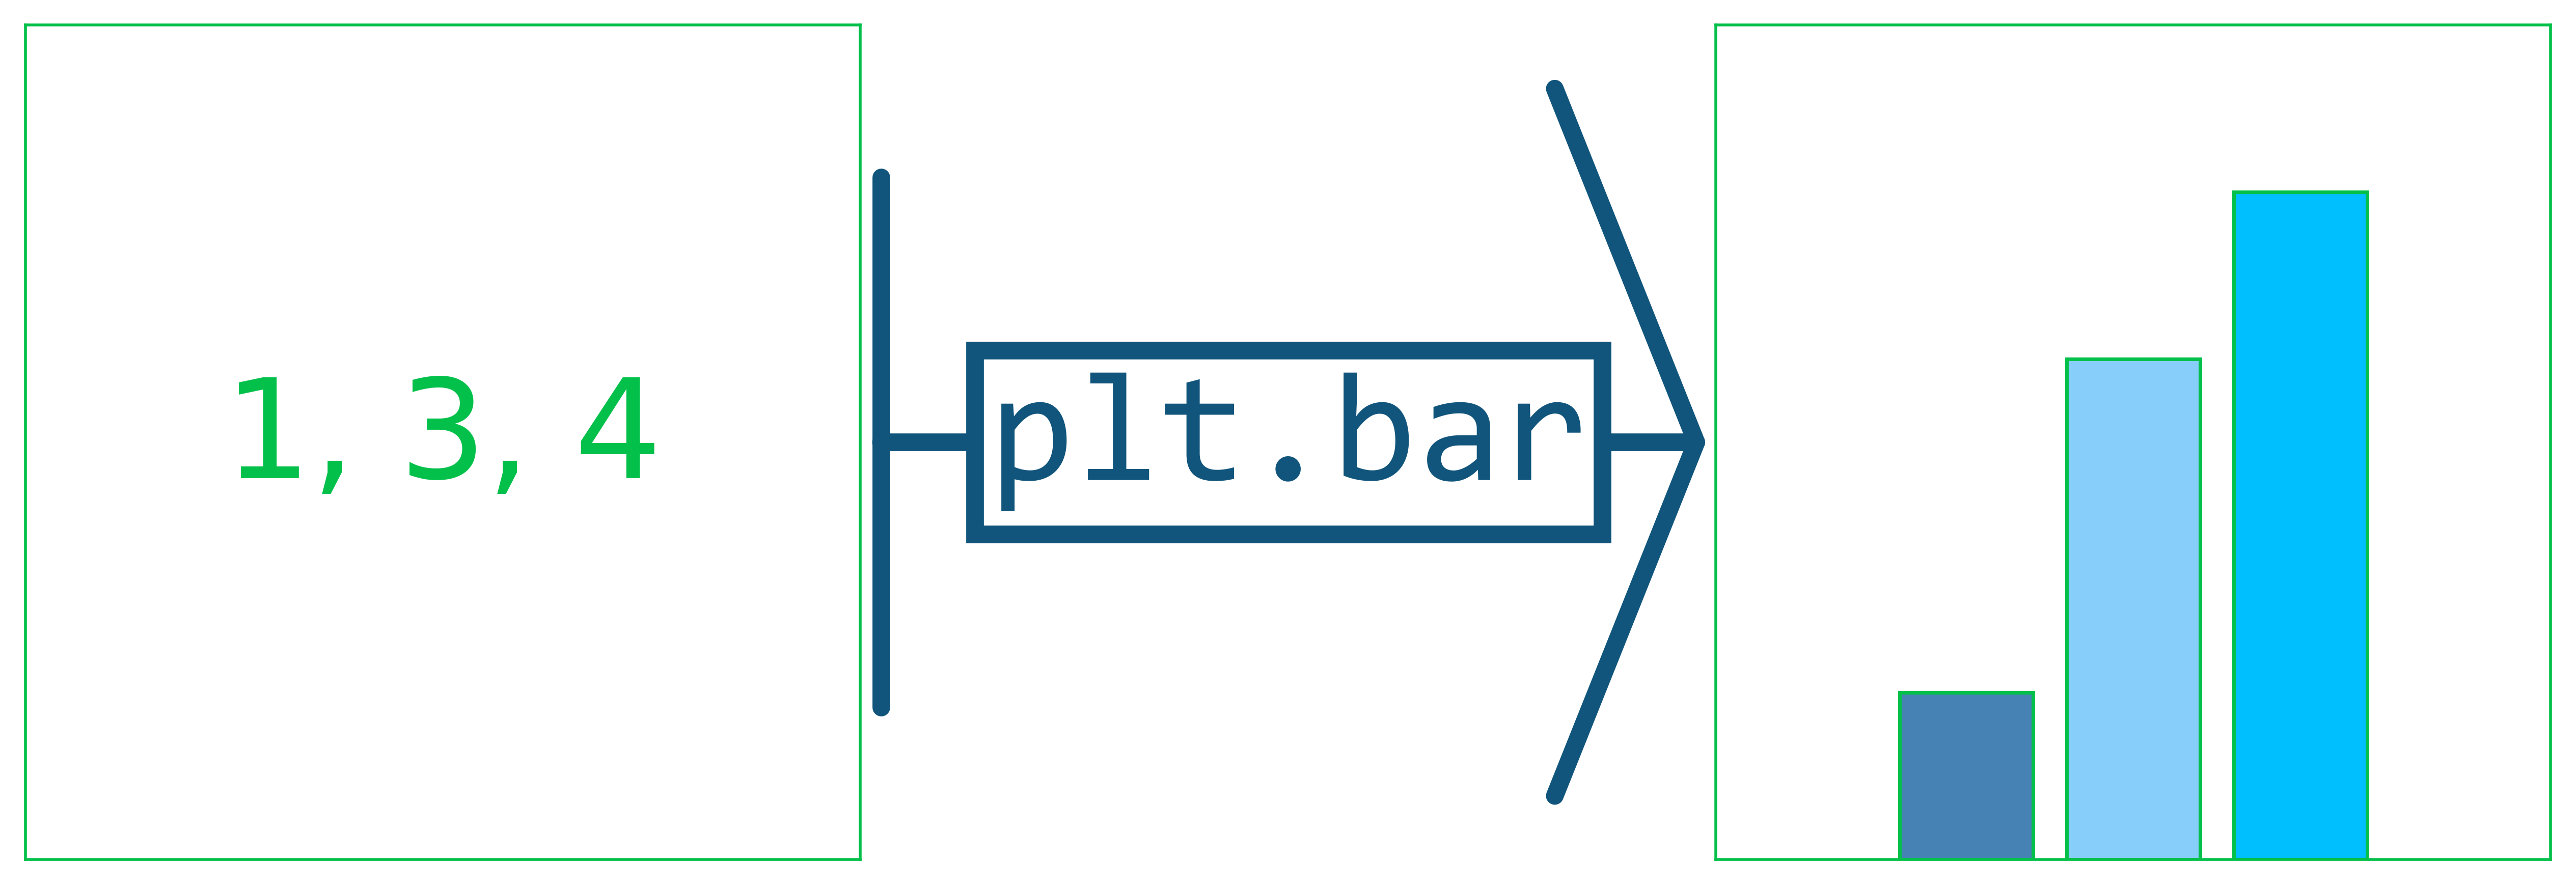

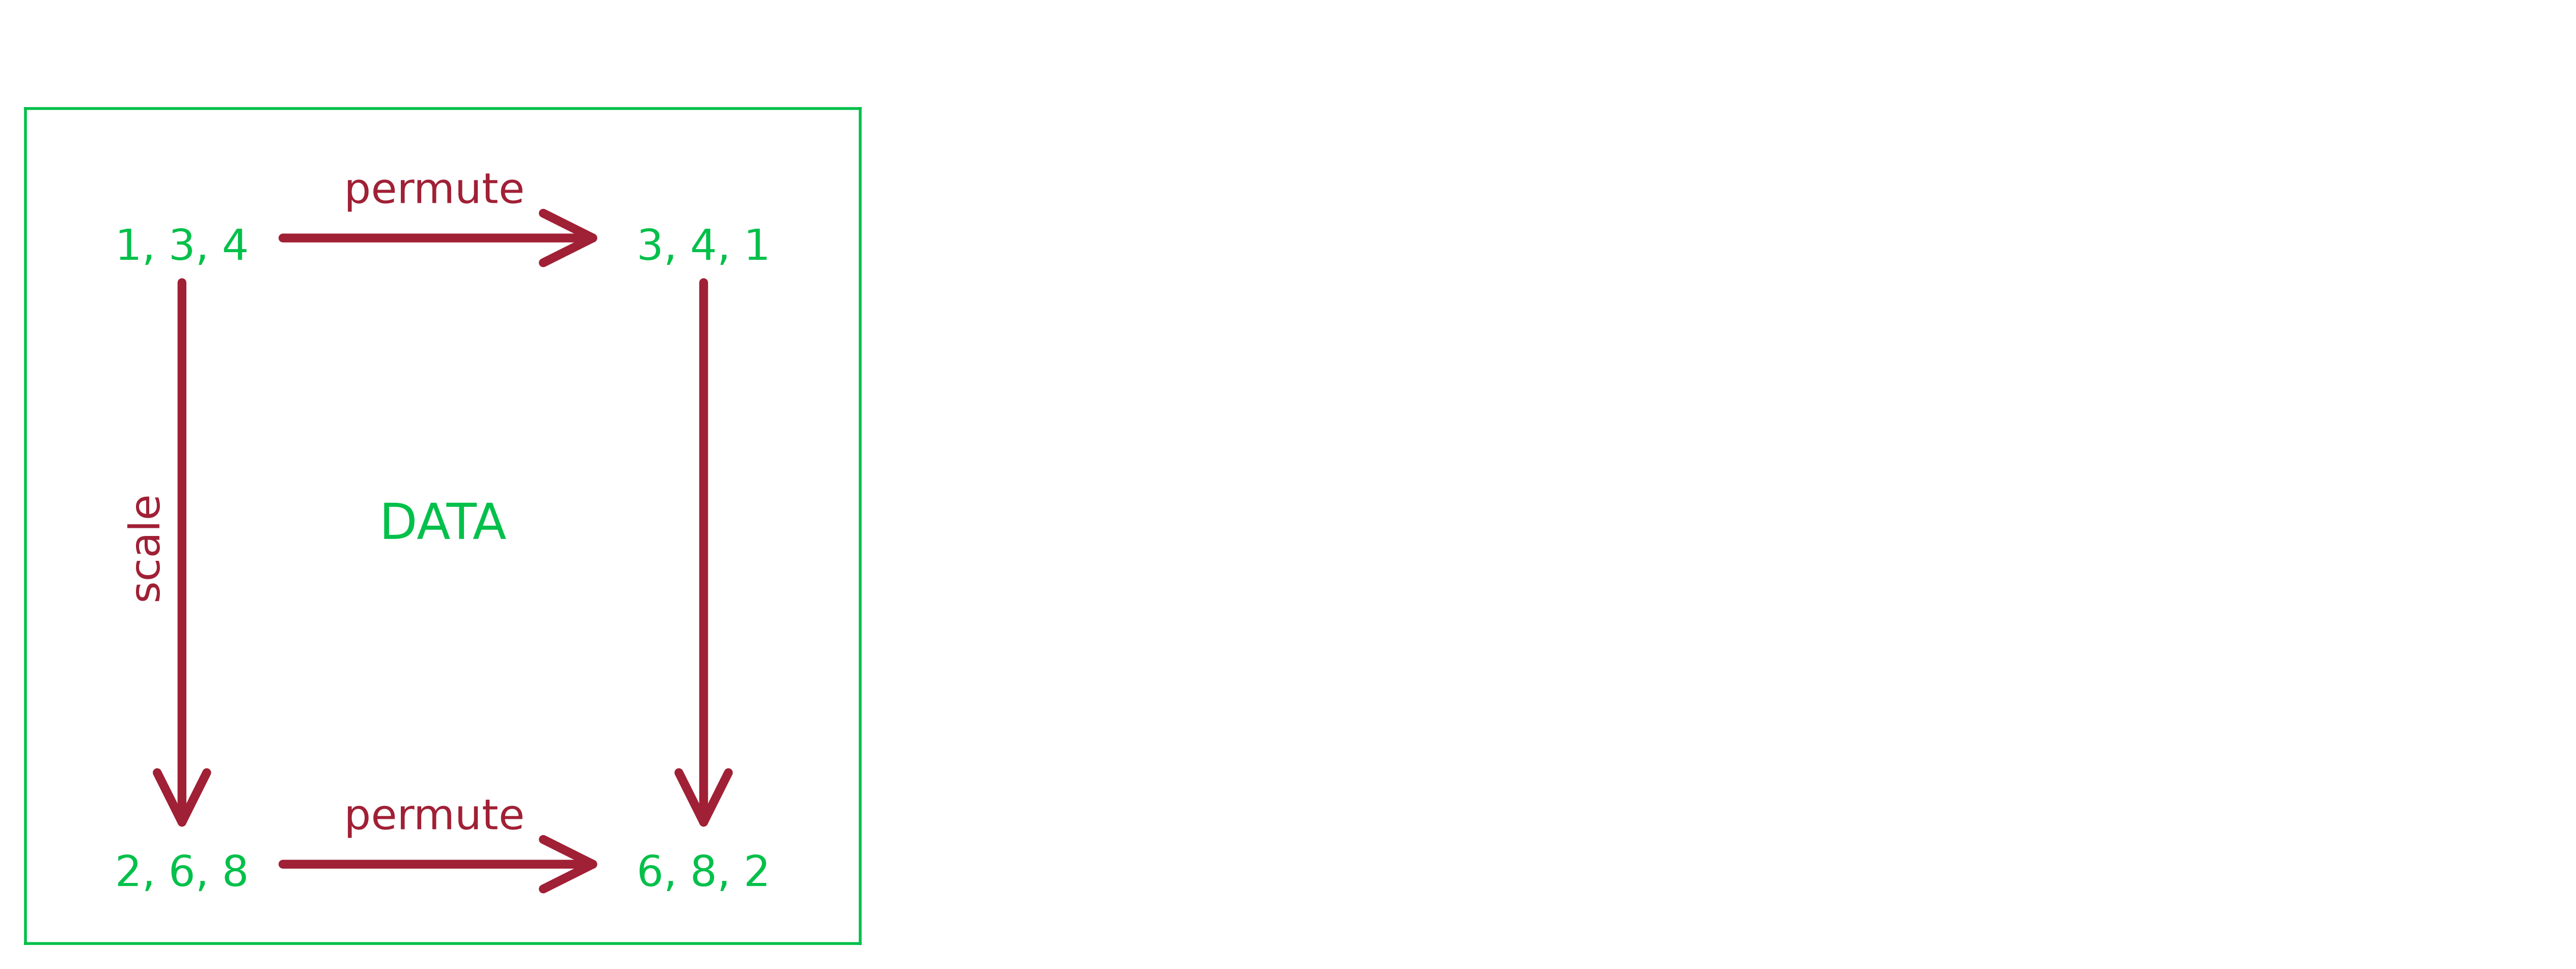

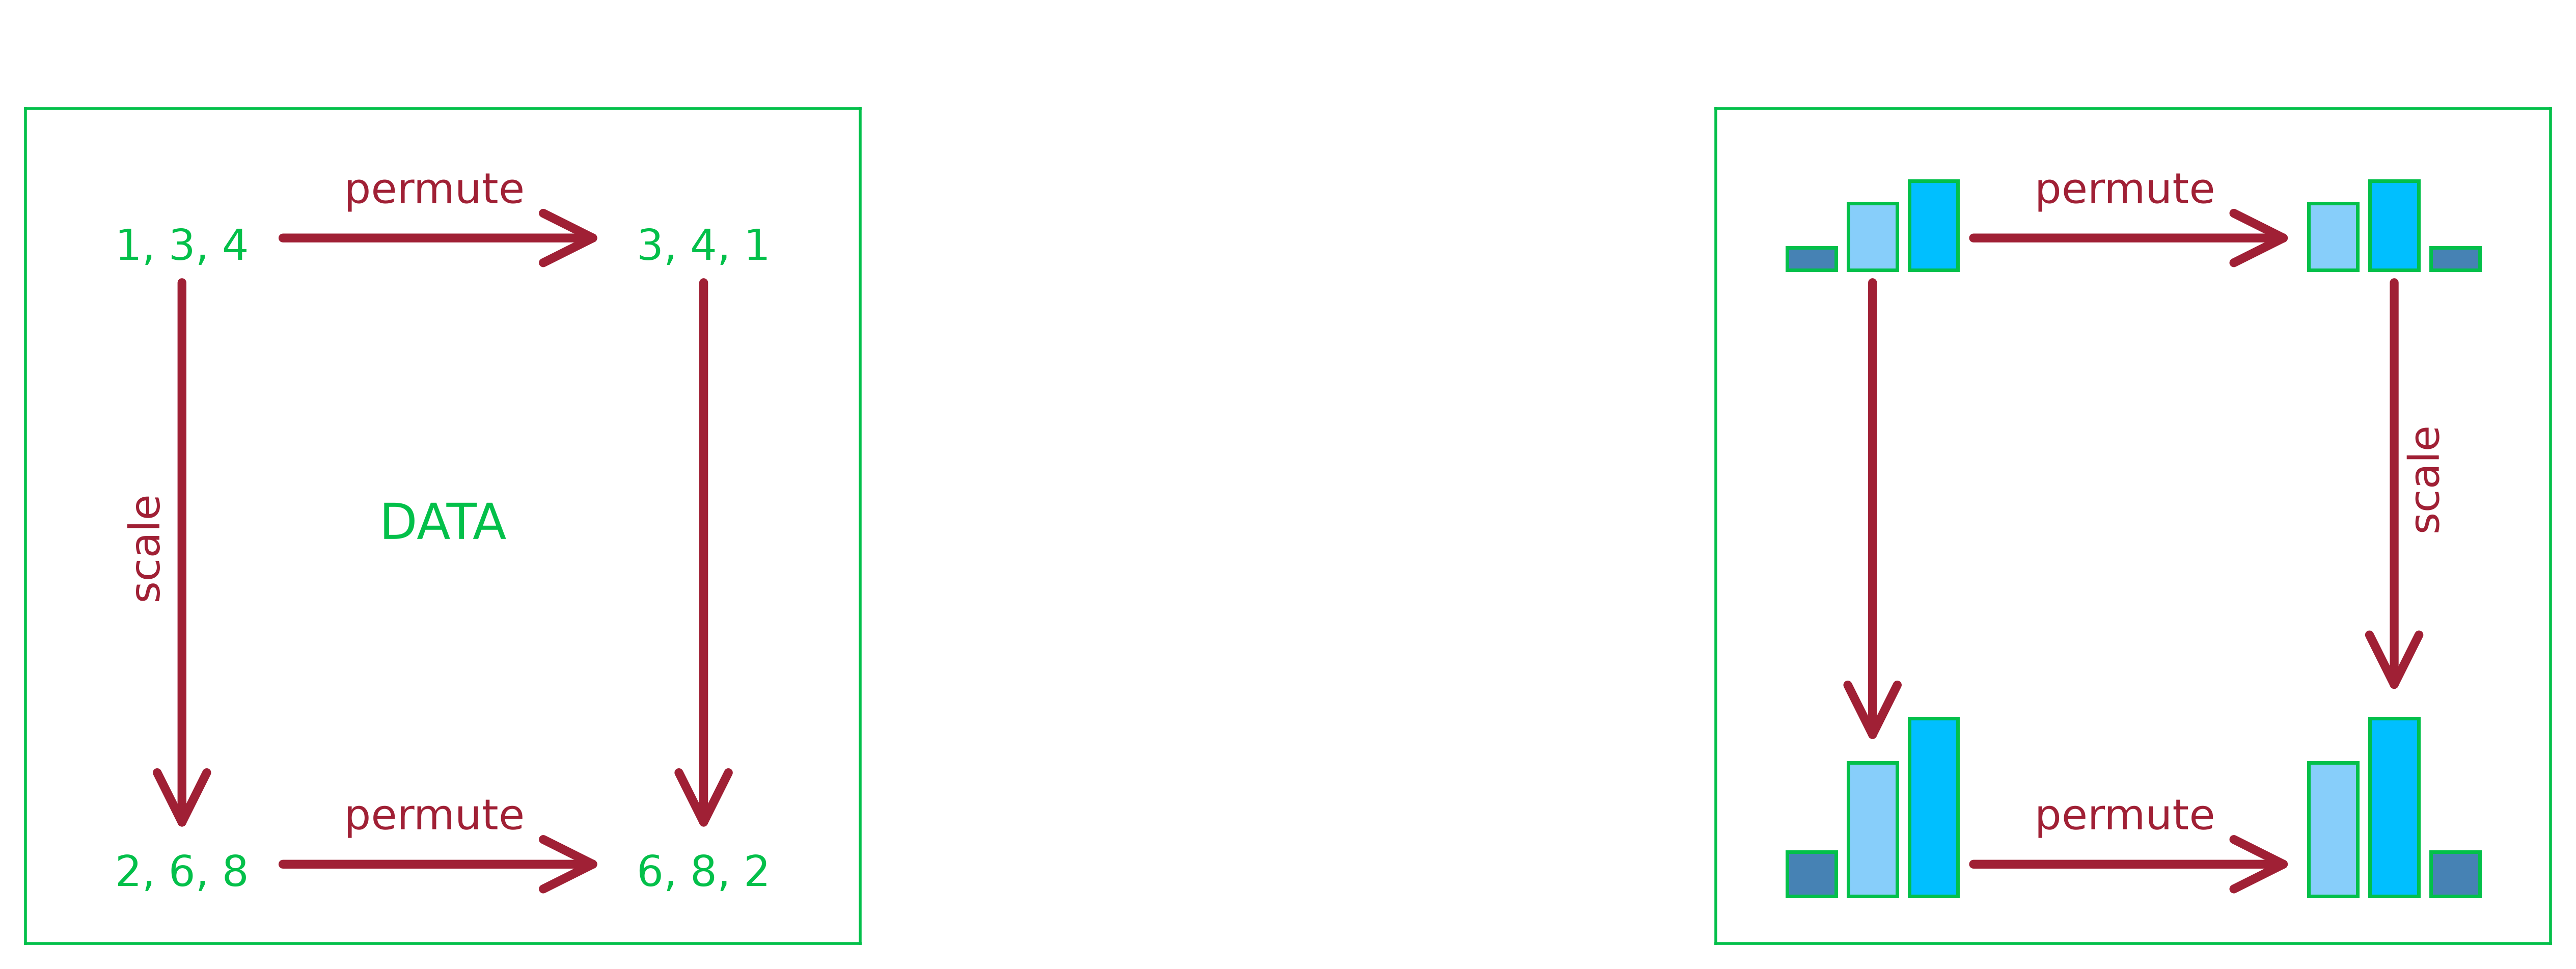

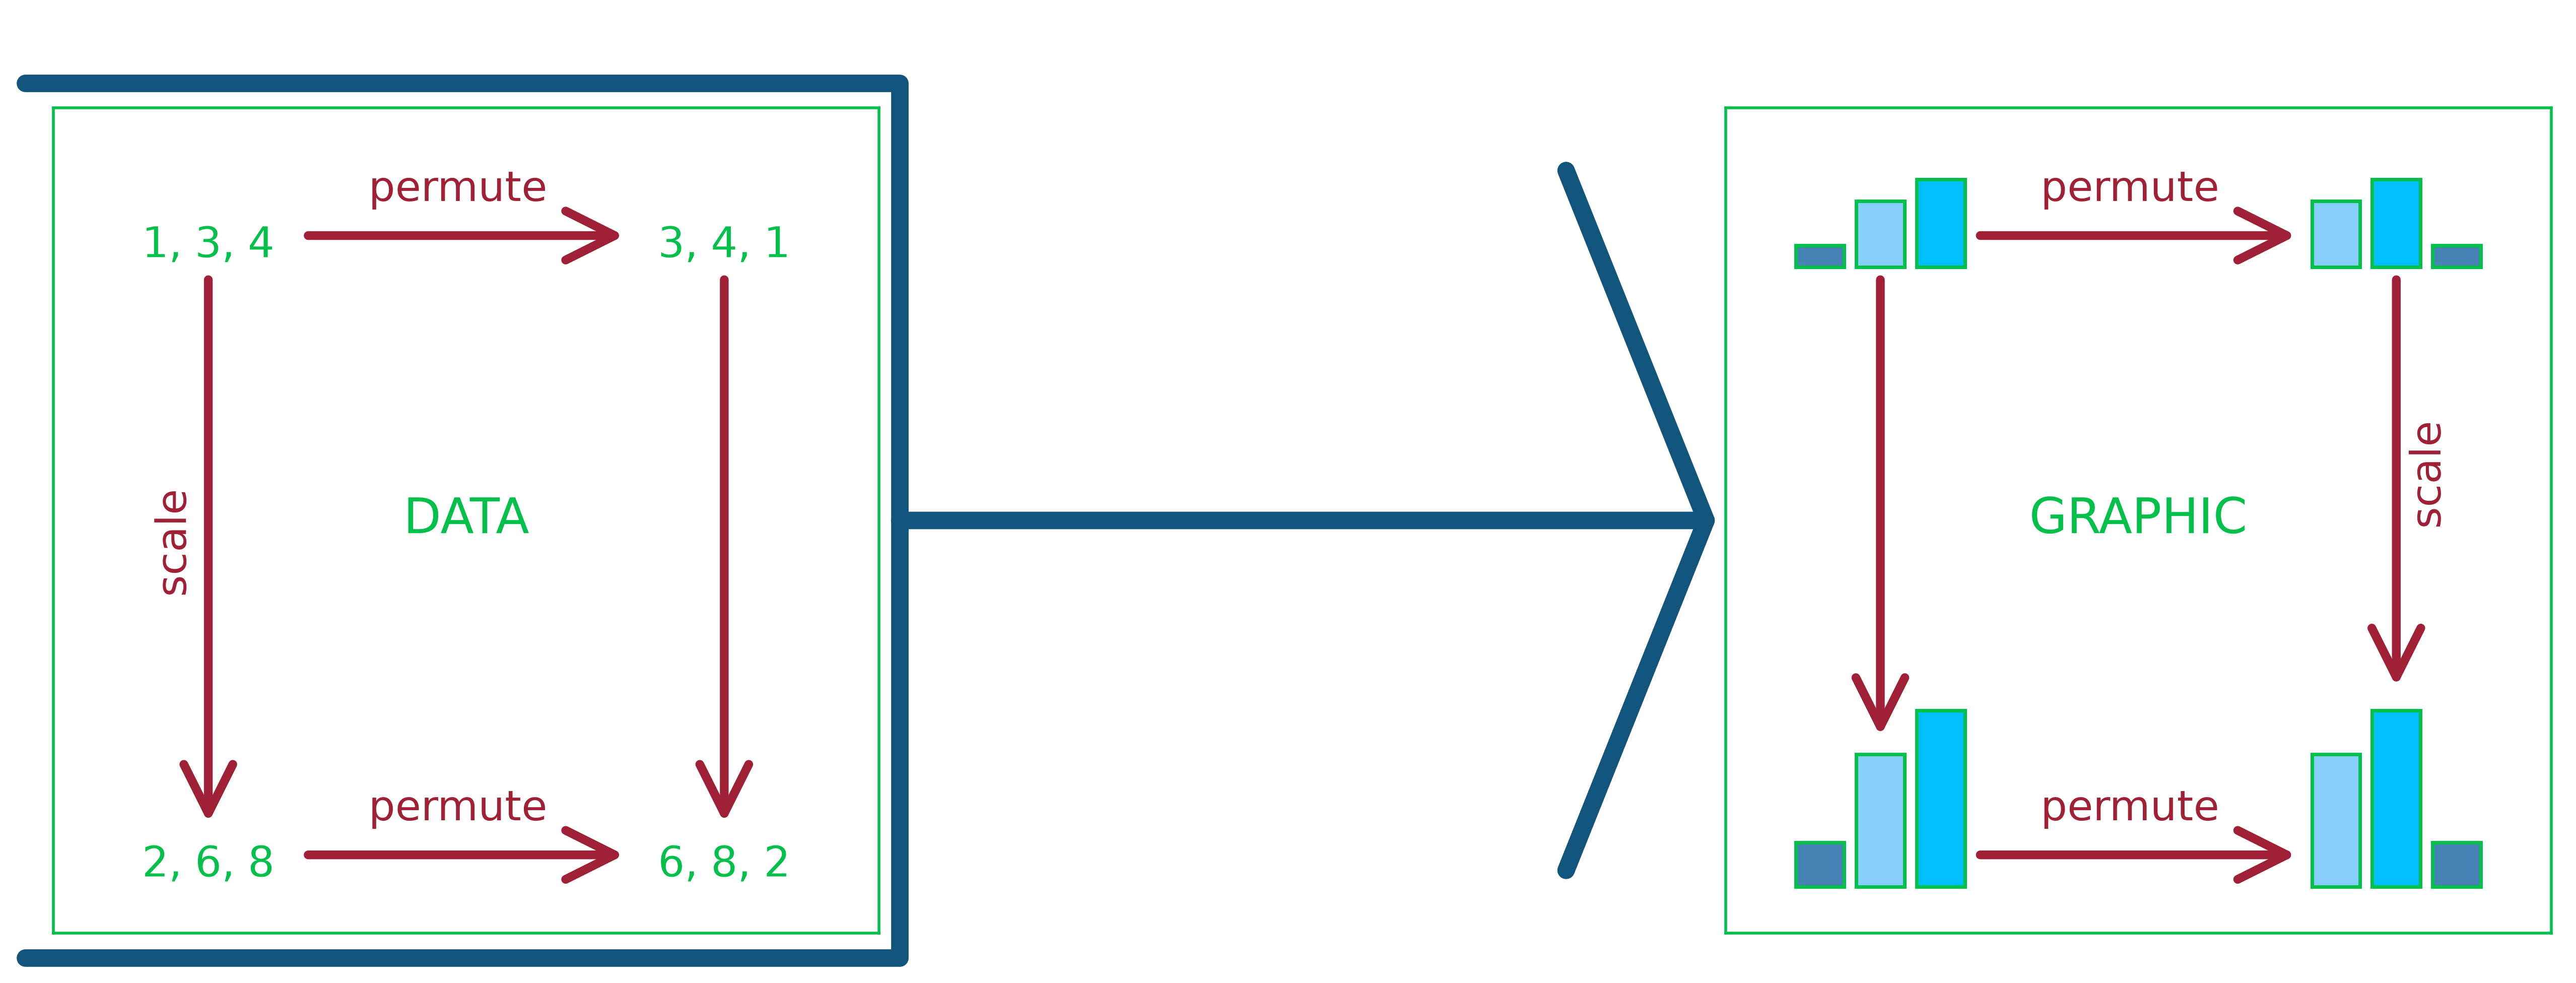

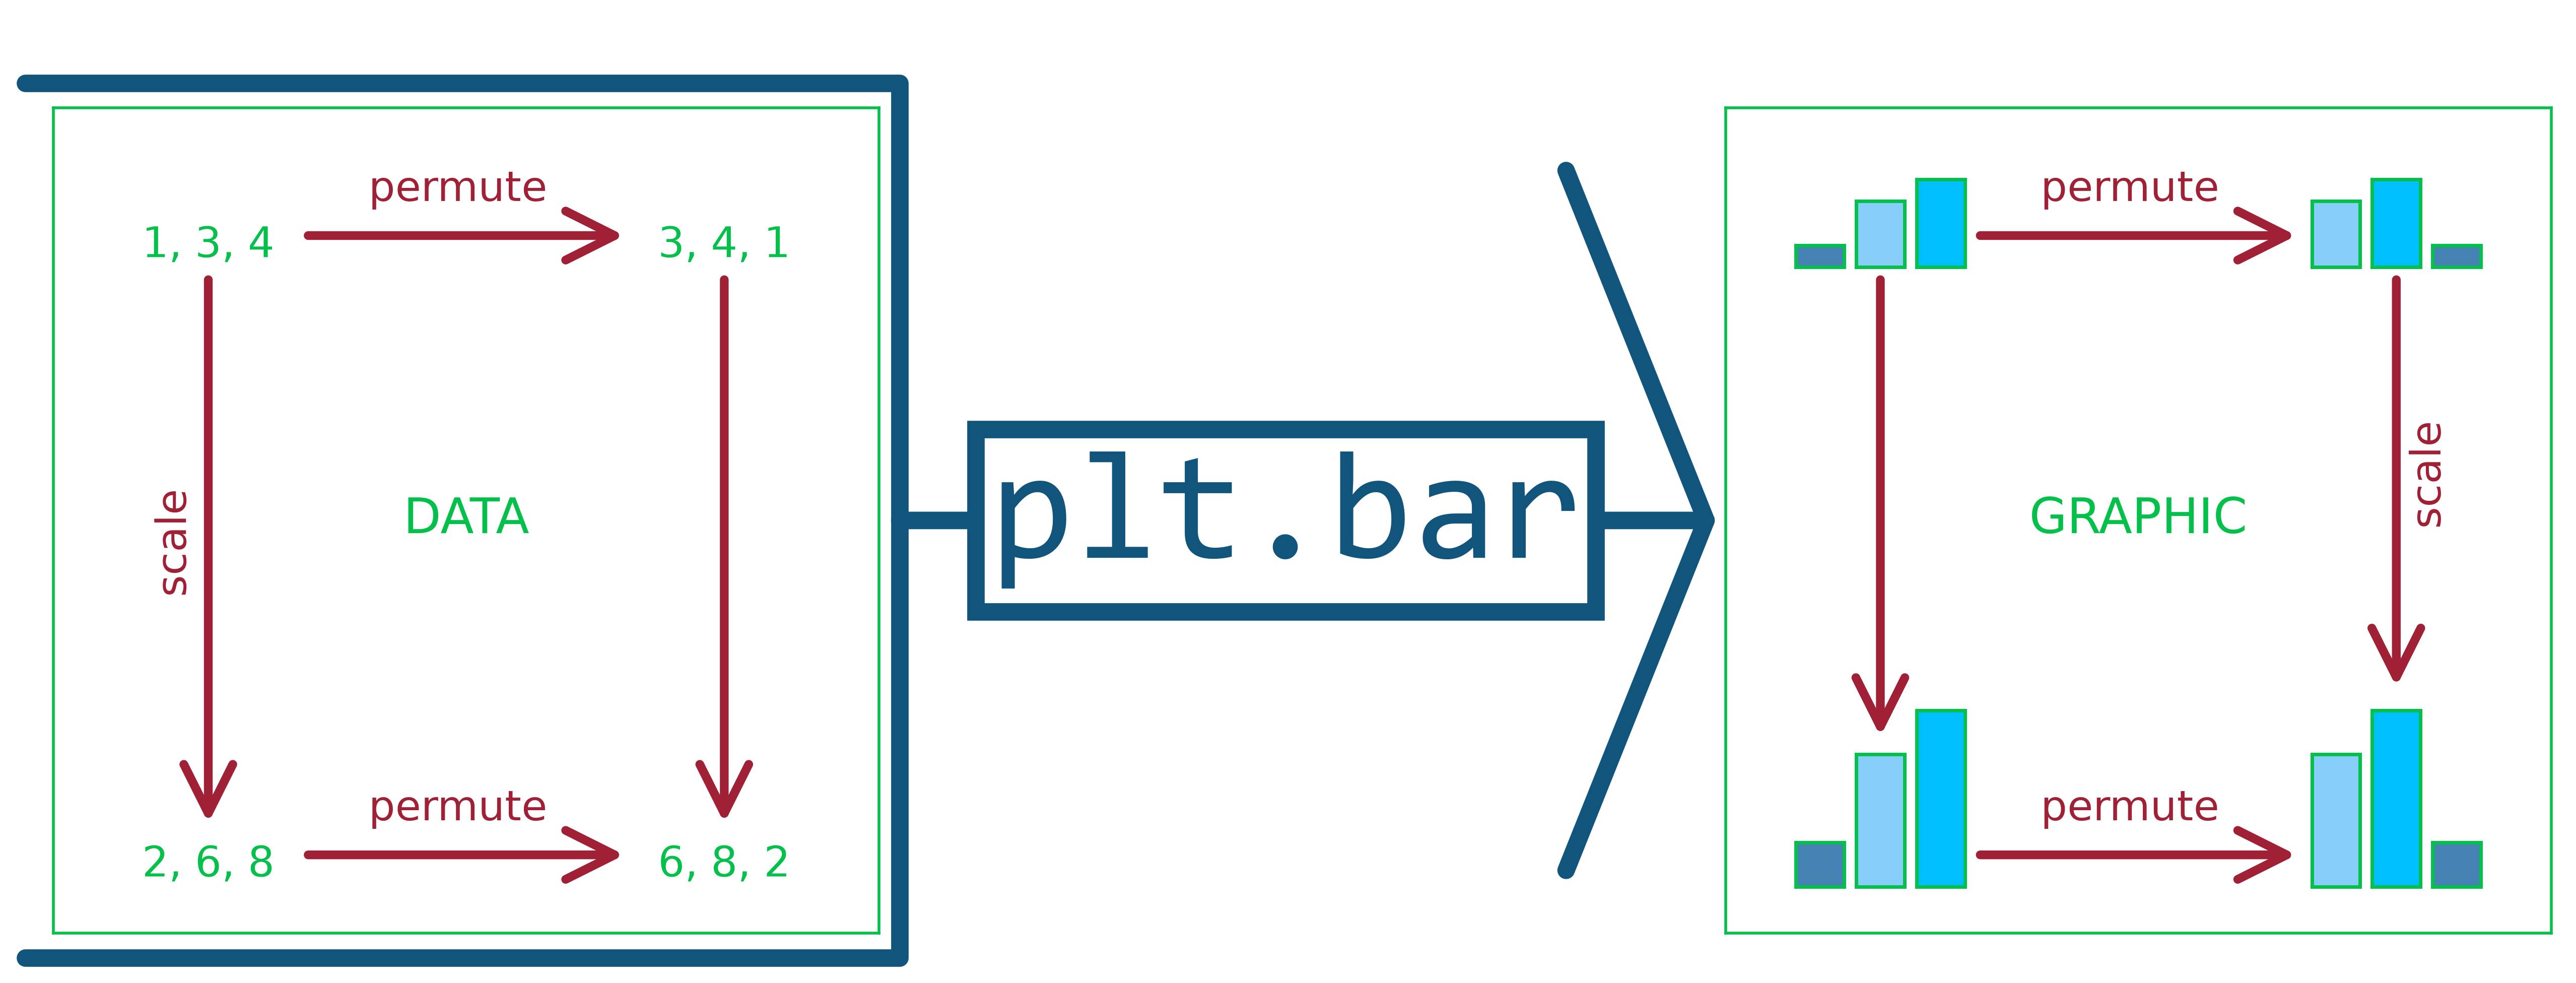

In [421]:
for i in range(6):
    slide_intro(i)